## Quantum Assignment

### Assignment Objective:
The primary objective is to Simulate a First-Order ODE on a Quantum Computer and comparing results with a classical method.

#### $\frac{dy}{dx} = -ky \text{, this is the ODE to solve}$

#### Initial condition $y(0) = 1$ and $k = 1$
### Tasks:
#### 1. State the exact analytical solution for the ODE and initial conditions at $y(1)$
#### 2. Solve the ODE numerically using a standard classical library
#### 3. Formulate a Quantum Algorithm which will model this ODE using a 2-qubit system


##### Hint: Consider the Kraus Operators and Formulate a Unitary to map on a single qubit. Populate the Unitary with the coefficients for all the basis states.

In [ ]:
!pip install -q qiskit qiskit-aer scipy matplotlib
!pip install qiskit qiskit-aer scipy matplotlib pylatexenc

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Operator, Statevector
from qiskit_aer import AerSimulator

# Assignment 1
Simulation of First Order ODE using Classical and Quantum Methods

ODE:
dy/dx = -ky

Initial condition:
y(0)=1

k=1

In [ ]:
k = 1
t = 1

exact = np.exp(-k*t)

print("Analytical Solution")
print(f"y(1) = {exact:.9f}")

Analytical Solution
y(1) = 0.367879441


The analytical solution is

y(x)=e^{-x}

Therefore,

y(1)=e^{-1}=0.367879441

Classical Numerical Solution

In [ ]:
def ode(t, y):
    return [-k*y[0]]

sol = solve_ivp(
    ode,
    [0,1],
    [1],
    t_eval=np.linspace(0,1,100)
)

classical = sol.y[0][-1]

print("Classical Numerical Solution")
print(classical)

Classical Numerical Solution
0.36809007647621717


Plot Analytical vs Classical

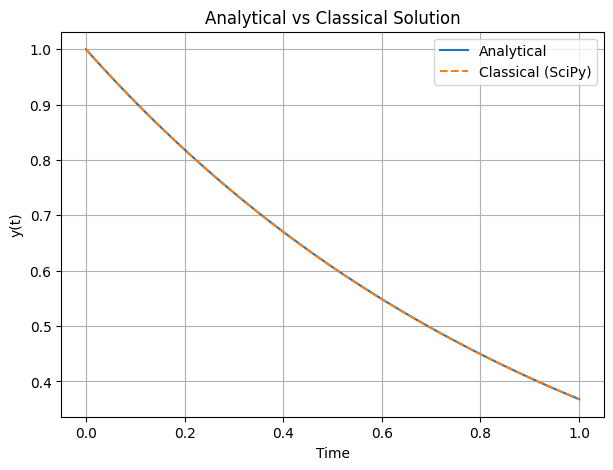

In [ ]:
t_values = np.linspace(0,1,100)

plt.figure(figsize=(7,5))

plt.plot(
    t_values,
    np.exp(-t_values),
    label="Analytical"
)

plt.plot(
    sol.t,
    sol.y[0],
    '--',
    label="Classical (SciPy)"
)

plt.xlabel("Time")

plt.ylabel("y(t)")

plt.title("Analytical vs Classical Solution")

plt.grid(True)

plt.legend()

plt.show()

Quantum Formulation

The exponential decay can be represented using the Amplitude Damping Channel.

The Kraus operators are

K0=[[1,0],[0,sqrt(1-p)]]

K1=[[0,sqrt(p)],[0,0]]

where

p=1-e^{-t}

These Kraus operators are embedded into a two-qubit unitary using an ancilla qubit.

In [ ]:
t = 1

p = 1 - np.exp(-t)

U = np.array([
    [1,0,0,0],
    [0,np.sqrt(1-p), np.sqrt(p),0],
    [0,-np.sqrt(p), np.sqrt(1-p),0],
    [0,0,0,1]
])

print("Unitary Matrix")

print(U)

Unitary Matrix
[[ 1.          0.          0.          0.        ]
 [ 0.          0.60653066  0.7950601   0.        ]
 [ 0.         -0.7950601   0.60653066  0.        ]
 [ 0.          0.          0.          1.        ]]


Build Quantum Circuit

In [ ]:
!pip install pylatexenc

In [ ]:
qc = QuantumCircuit(2)

# Prepare |10>

qc.x(0)

qc.unitary(Operator(U), [0,1])

qc.measure_all()

print(qc)

        ┌───┐┌──────────┐ ░ ┌─┐   
   q_0: ┤ X ├┤0         ├─░─┤M├───
        └───┘│  Unitary │ ░ └╥┘┌─┐
   q_1: ─────┤1         ├─░──╫─┤M├
             └──────────┘ ░  ║ └╥┘
meas: 2/═════════════════════╩══╩═
                             0  1 


Run Quantum Simulation

In [ ]:
sim = AerSimulator()

compiled = transpile(qc, sim)

result = sim.run(
    compiled,
    shots=100000
).result()

counts = result.get_counts()

print(counts)

{'10': 63322, '01': 36678}


Compute Quantum Probability

In [ ]:
shots = sum(counts.values())

for state, count in counts.items():
    print(state, count/shots)

quantum = counts.get("01",0)/shots

print()

print("Quantum Probability =", quantum)

10 0.63322
01 0.36678

Quantum Probability = 0.36678


Obtain Exact Statevector

In [ ]:
qc2 = QuantumCircuit(2)

qc2.x(0)

qc2.unitary(Operator(U), [0,1])

state = Statevector.from_instruction(qc2)

print(state)

Statevector([ 0.        +0.j,  0.60653066+0.j, -0.7950601 +0.j,
              0.        +0.j],
            dims=(2, 2))


In [ ]:
print("="*45)

print("Comparison of Results")

print("="*45)

print(f"Analytical : {exact:.9f}")

print(f"Classical  : {classical:.9f}")

print(f"Quantum    : {quantum:.9f}")

print()

print(f"Classical Error = {abs(classical-exact):.8f}")

print(f"Quantum Error   = {abs(quantum-exact):.8f}")

Comparison of Results
Analytical : 0.367879441
Classical  : 0.368090076
Quantum    : 0.366780000

Classical Error = 0.00021064
Quantum Error   = 0.00109944


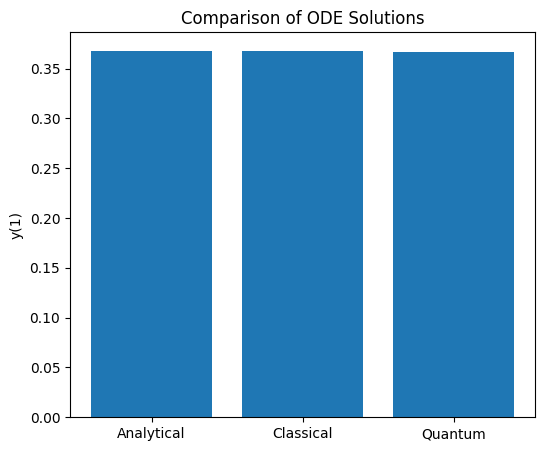

In [ ]:
methods = ["Analytical","Classical","Quantum"]

values = [exact,classical,quantum]

plt.figure(figsize=(6,5))

plt.bar(methods, values)

plt.ylabel("y(1)")

plt.title("Comparison of ODE Solutions")

plt.show()